# Greek Letters Calculation

### 1. Goal:

Implement and compare analytical and numerical approaches for computing Delta and Vega of European call options under the Black–Scholes–Merton model.

### 2. Preliminary

Take European call option for example. We know the Black-Scholes-Merton formula for the call option:

$$
c=S_0N(d_+)-Ke^{-rT}N(d_-),
$$

$$
d_\pm=\frac{1}{\sigma \sqrt{T}}\left[ \log\frac{S_0}{K}+(r\pm \frac{1}{2}\sigma^2)T\right],
$$

where $N$ is the cumulative distribution function for the standard normal distribution. From the definiton of Greek letters, we derive that 

$$
\Delta=\frac{\partial c}{\partial S_0}=N(d_+),
$$

and 

$$
\mathrm{Vega}=\frac{\partial c}{\partial \sigma}=S_0\sqrt{T}\phi(d_+). 
$$

Here $\phi(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2}$ is the probability density function for $X\sim N(0,1)$.

### 3. Strategy

For the finite difference method, we complete this in two aspects:

- 1. bump and reprice.

$$
\Delta \approx \frac{c(S_0+h)-c(S_0-h)}{2h},\qquad 
\mathrm{Vega}\approx \frac{c(\sigma+h)-c(\sigma-h)}{2h}. 
$$

- 2. PDE solver via finite difference. We use the explicit finite difference method to formulate the PDE solver for the BS equation.

### 4. PDE Solver

We divide the life $T$ of option into $N$ equally spaced intervals of length $\Delta t=T/N$. A total of $N+1$ times are considered

$$
0,\,\Delta t,\,2\Delta t,\,\cdots,\,T. 
$$

Suppose $S_{max}$ is a stock price sufficiently high that, when it is reached, the call is sufficiently deep in the money. Define $\Delta S=S_{max}/M$ and consider a total of $M+1$ equally spaced stock prices:

$$
0,\,\Delta S,\,2\Delta S,\,\cdots,\,S_{max}. 
$$

Denote $c_{i,j}=c(i\Delta t,j\Delta S)$. For interior point $(i,j)$, we have the approximation

$$
\frac{\partial c}{\partial t}=\frac{c_{i+1,j}-c_{i,j}}{\Delta t},
$$

$$
\frac{\partial c}{\partial S}=\frac{c_{i+1,j+1}-c_{i+1,j-1}}{2\Delta S},
$$

and 

$$
\frac{\partial^2 c}{\partial S^2}=\frac{c_{i+1,j+1}+c_{i+1,j-1}-2c_{i+1,j}}{\Delta S^2}. 
$$

Substitute the above expressions into the BS equation 

$$
c_t+rSc_S+\frac{1}{2}\sigma^2 S^2 c_{SS}-rc=0
$$

to get the explicit iteration formula

$$
c_{i,j}=a_j c_{i+1,j-1}+b_j c_{i+1,j}+c_j^* c_{i+1,j+1},
$$

where 

$$
\begin{aligned}
&a_j=\frac{1}{1+r\Delta t}(-\frac{1}{2}rj\Delta t+\frac{1}{2}\sigma^2 j^2\Delta t),\\
&b_j=\frac{1}{1+r\Delta t}(1-\sigma^2j^2\Delta t),\\
&c_j^*=\frac{1}{1+r\Delta t}(\frac{1}{2}rj\Delta t+\frac{1}{2}\sigma^2j^2\Delta t). 
\end{aligned}
$$

We impose the boundary condition

$$
c_{N,j}=\max(j\Delta S-K,0),
$$

$$
c_{i,0}=0,\qquad c_{i,M}=S_{max}-e^{-r(T-i\Delta t)}K. 
$$

The upper boundary condition is based on the asymptotic behavior of the European call price as $S\to\infty$. Fixing a finite $S_{\max}$ introduces an additional domain truncation error.

> **Remark** To ensure that the explicit scheme has nonnegative coefficients, we impose the sufficient conditions
> $$
\sigma^2 \geq r,\qquad 
\sigma^2(M-1)^2\Delta t \leq 1. 
> $$
> Under these conditions, the numerical scheme is monotone and stable in the maximum norm, for prescribed bounded boundary and terminal data.

### 5. Python Implementation

In [1]:
import numpy as np
import matplotlib.pyplot as plt 
from scipy import stats

# Black-Scholes formula for a European call option
def black_scholes_call(S0,K,T,r,sigma):
    d1=1/(sigma*np.sqrt(T))*(np.log(S0/K)+(r+sigma**2/2)*T)
    d2=d1-sigma*np.sqrt(T)
    call=S0*stats.norm.cdf(d1)-K*np.exp(-r*T)*stats.norm.cdf(d2)
    return call

# Analytic formula for Greeks
def delta_Greeks(S0,K,T,r,sigma):
    d1=1/(sigma*np.sqrt(T))*(np.log(S0/K)+(r+sigma**2/2)*T)
    delta=stats.norm.cdf(d1)
    return delta

def vega_Greeks(S0,K,T,r,sigma):
    d1=1/(sigma*np.sqrt(T))*(np.log(S0/K)+(r+sigma**2/2)*T)
    vega=S0*np.sqrt(T)*stats.norm.pdf(d1)
    return vega 

# Central difference method
def delta_central(S0,K,T,r,sigma,h):
    call_forward=black_scholes_call(S0+h,K,T,r,sigma)
    call_backward=black_scholes_call(S0-h,K,T,r,sigma)
    delta=(call_forward-call_backward)/(2*h)
    return delta 

def vega_central(S0,K,T,r,sigma,h):
    call_forward=black_scholes_call(S0,K,T,r,sigma+h)
    call_backward=black_scholes_call(S0,K,T,r,sigma-h)
    vega=(call_forward-call_backward)/(2*h)
    return vega 

### 6. Finite difference PDE solver

In [2]:
def finite_difference_PDEsolver(T,K,r,sigma,N,M,Smax):
    dt=T/N
    dS=Smax/M

    S=np.arange(M+1)*dS
    t=np.arange(N+1)*dt 
    j=np.arange(M+1)

    c=np.zeros((N+1,M+1))

    # Terminal condition
    c[N,:]=np.maximum(S-K,0)

    # Boundary conditions
    c[:,0]=0
    c[:,-1]=Smax-K*np.exp(-r*(T-t))

    #Stability warning
    if sigma**2*(M-1)**2*dt>1:
        print('Warning: time step may be too large.')

    #Finite difference coefficients
    a=dt*(sigma**2*j**2-r*j)/(2*(1+r*dt))
    b=(1-sigma**2*j**2*dt)/(1+r*dt)
    cc=dt*(sigma**2*j**2+r*j)/(2*(1+r*dt))
    
    # Backward iteration
    for i in range(N-1,-1,-1):
        c[i,1:-1]=a[1:-1]*c[i+1,:-2]+b[1:-1]*c[i+1,1:-1]+cc[1:-1]*c[i+1,2:]
    
    return S,c[0,:]


### 7. Experiment

Consider a $6$-month European call option on a non-dividend-paying stock when the stock price is $\$50$, the strike price is $\$50$, the risk-free interest rate is $10\%$ per annum, and the volatility is $40\%$ per annum. With our notation, this means that $S0=50,K=50,r=0.1,\sigma=0.4$ and $T=0.5$.

The analytic value for The Greek letter is:
 Delta=0.6248, Vega=13.4085.

Take h in [10, 8, 5, 3, 1, 0.5, 0.1, 0.05, 0.01, 0.005] respectively, 
the central difference value delta=[0.6074 0.6133 0.6202 0.6231 0.6246 0.6248 0.6248 0.6248 0.6248 0.6248].
Take h in [0.1, 0.05, 0.02, 0.01, 0.005] respectively, 
the central difference value vega=[13.3917 13.4044 13.4078 13.4083 13.4084]


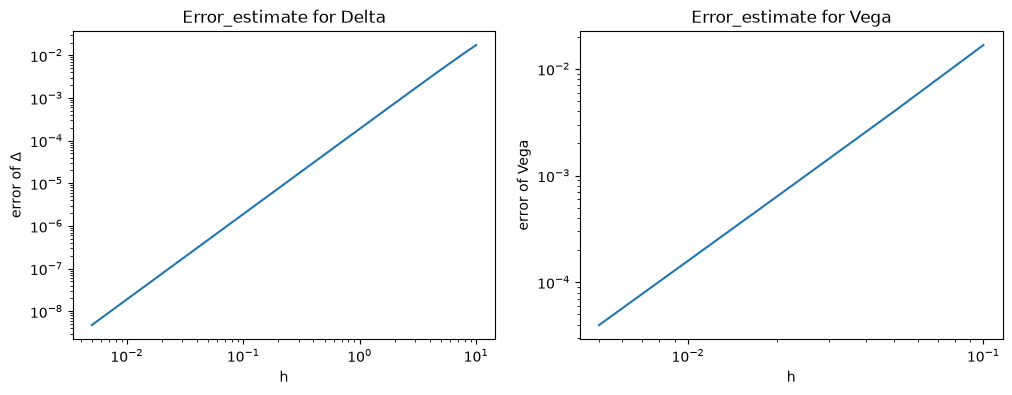

Estimate slope=1.9928 for delta.
Estimate slope=2.0153 for vega.


In [3]:
S0=50;K=50;r=0.1;sigma=0.4;T=0.5
h_interval=[10,8,5,3,1,0.5,0.1,0.05,0.01,0.005]
h_vega=[0.1,0.05,0.02,0.01,0.005]

delta=delta_Greeks(S0,K,T,r,sigma)
vega=vega_Greeks(S0,K,T,r,sigma)

delta_center=[]
vega_center=[]
for h in h_interval:
    delta_center.append(delta_central(S0,K,T,r,sigma,h))
for h1 in h_vega:
    vega_center.append(vega_central(S0,K,T,r,sigma,h1))


print(f'The analytic value for The Greek letter is:\n Delta={delta:.4f}, Vega={vega:.4f}.')
print()
print(f'Take h in {h_interval} respectively, \nthe central difference value delta={np.round(np.array(delta_center),4)}.')
print(f'Take h in {h_vega} respectively, \nthe central difference value vega={np.round(np.array(vega_center),4)}')
#Plot
h_interval=np.array(h_interval)
h_vega=np.array(h_vega)
error_delta=np.abs(delta_center-delta)
error_vega=np.abs(vega_center-vega)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].loglog(h_interval,error_delta)
ax[0].set_title('Error_estimate for Delta')
ax[0].set_xlabel('h')
ax[0].set_ylabel(r'error of $\Delta$')

ax[1].loglog(h_vega,error_vega)
ax[1].set_title('Error_estimate for Vega')
ax[1].set_xlabel('h')
ax[1].set_ylabel(r'error of $\mathrm{Vega}$')
plt.show()

#Convergence rate estimate
slope,intercept=np.polyfit(np.log(h_interval),np.log(error_delta),1)
print(f'Estimate slope={slope:.4f} for delta.')

slope2,intercept2=np.polyfit(np.log(h_vega),np.log(error_vega),1)
print(f'Estimate slope={slope2:.4f} for vega.')


In the following, take $N=\lambda \sigma^2 M^2T$, $\lambda=1.6$ to ensure all the coefficients $a_j,b_j,c_j^*$ be positive.

The exact option price from BS formula is: 6.7902.
The call price from explicit finite difference formula are: 
 [4.7847 6.4707 6.7159 6.7785 6.7873] when M take the value [4, 10, 20, 50, 100] respectively.


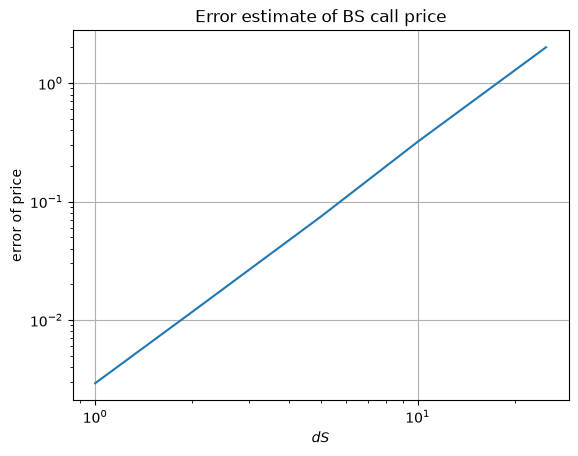

Estimate slope=2.0338 for call price.

The exact Delta using BS formula is delta=0.6248.
Delta from PDE solver are [0.5504 0.6089 0.6215 0.6243 0.6247].


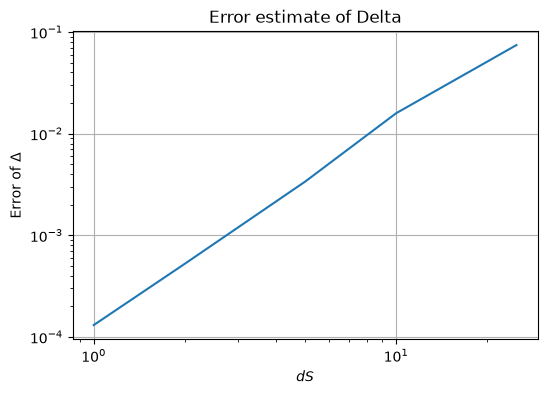

Estimate slope=1.9983 for delta.


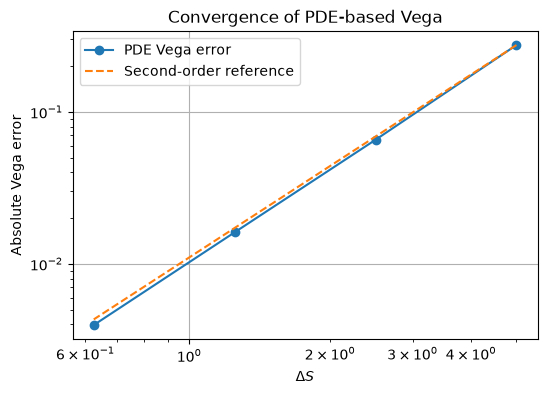

Estimate convergence order: 2.0395.


In [4]:
Smax=100
M_interval=[4,10,20,50,100]
N_interval=[2,12,48,300,1200]

#PDE solver compared with exact BS formula
call=black_scholes_call(S0,K,T,r,sigma)
call_solver=[]
for i in range(len(M_interval)):
    M=M_interval[i]
    N=N_interval[i]
    temp_S,temp_call=finite_difference_PDEsolver(T,K,r,sigma,N,M,Smax)
    idx=S0//(Smax//M)
    call_solver.append(temp_call[idx])
call_solver=np.array(call_solver)

print(f'The exact option price from BS formula is: {call:.4f}.')
print(f'The call price from explicit finite difference formula are: \n {np.round(call_solver,4)} when M take the value {M_interval} respectively.')

#Plot the error of call price
error_call=np.abs(call_solver-call)
dS=Smax/np.array(M_interval)
plt.loglog(dS,error_call)
plt.xlabel(r'$dS$')
plt.ylabel(r'error of price')
plt.title(r'Error estimate of BS call price')
plt.grid()
plt.show()
slope,intercept=np.polyfit(np.log(dS),np.log(error_call),1)
print(f'Estimate slope={slope:.4f} for call price.')

#Estimate of Delta
delta=delta_Greeks(S0,K,T,r,sigma)
vega=vega_Greeks(S0,K,T,r,sigma)
delta_solver=[]
for i in range(len(M_interval)):
    M=M_interval[i]
    N=N_interval[i]
    temp_S,temp_call=finite_difference_PDEsolver(T,K,r,sigma,N,M,Smax)
    dS=Smax/M
    idx=np.argmin(np.abs(temp_S-S0))
    temp_delta=(temp_call[idx+1]-temp_call[idx-1])/(2*dS)
    delta_solver.append(temp_delta)
delta_solver=np.array(delta_solver)
print()
print(f'The exact Delta using BS formula is delta={delta:.4f}.')
print(f'Delta from PDE solver are {np.round(delta_solver,4)}.')

#Plot error of Delta
dS=np.array([Smax/M for M in M_interval])
error_delta_solver=np.abs(delta_solver-delta)

plt.figure(figsize=(6,4))
plt.loglog(dS,error_delta_solver)
plt.xlabel(r'$dS$')
plt.ylabel(r'Error of $\Delta$')
plt.title(r'Error estimate of Delta')
plt.grid()

plt.show()
slop3,intercept3=np.polyfit(np.log(dS),np.log(error_delta_solver),1)
print(f'Estimate slope={slop3:.4f} for delta.')

# Vega convergence study: refine the PDE grid
M_interval=np.array([20,40,80,160])
dSigma=0.002

vega_exact=vega_Greeks(S0,K,T,r,sigma)
vega_solver=[]

for M in M_interval:
    #Stability condition for the largest volatility
    sigma_max=sigma+dSigma

    N=int(np.ceil(2*T*sigma_max**2*(M-1)**2))

    S_plus,call_plus=finite_difference_PDEsolver(T,K,r,sigma+dSigma,N,M,Smax)
    S_minus,call_minus=finite_difference_PDEsolver(T,K,r,sigma-dSigma,N,M,Smax)

    idx=np.argmin(np.abs(S_plus-S0))

    vega_num=(call_plus[idx]-call_minus[idx])/(2*dSigma)
    vega_solver.append(vega_num)

vega_solver=np.array(vega_solver)

dS=Smax/M_interval
error_vega=np.abs(vega_solver-vega_exact)

slop,intercept=np.polyfit(np.log(dS),np.log(error_vega),1)

plt.figure(figsize=(6,4))
plt.loglog(dS,error_vega,'o-',label='PDE Vega error')

reference=error_vega[0]*(dS/dS[0])**2
plt.loglog(dS,reference,'--',label='Second-order reference')
plt.xlabel(r'$\Delta S$')
plt.ylabel('Absolute Vega error')
plt.title('Convergence of PDE-based Vega')
plt.grid(True)
plt.legend()
plt.show()

print(f'Estimate convergence order: {slop:.4f}.')


## 8. Conclusion

In this project, we implemented and compared numerical methods for computing Delta and Vega under the Black–Scholes–Merton model.

For the bump-and-reprice method, central finite differences were applied to the analytical option pricing formula. The numerical experiments demonstrated approximately second-order convergence for both Delta and Vega, consistent with the theoretical truncation error of \(O(h^2)\).

For the PDE-based approach, we implemented an explicit finite difference scheme for the Black–Scholes equation. Under the chosen parameters and the time-step scaling \(\Delta t=O((\Delta S)^2)\), the numerical errors in the option price and Delta exhibited approximately second-order convergence.

For PDE-based Vega, we observed that decreasing the volatility bump while keeping the PDE grid fixed does not eliminate the underlying PDE discretization error. By refining the spatial grid and adjusting the time step accordingly, we obtained approximately second-order convergence over the tested grid resolutions.

These experiments illustrate the importance of distinguishing numerical differentiation errors from PDE discretization errors when computing option Greeks.